# Random Forest Model

 Instead of training a single decision tree, Random Forest trains a large number of trees and combines their predictions.

The key idea is that a group of weakly correlated models can produce a stronger predictor than any individual model.

This reduces correlation between trees and improves generalization.

## Why Random Forest should work well for this problem

From our exploratory data analysis we observed:

- Strong non-linear relationships between **late payments and default risk**
- Highly skewed distributions
- Outliers in features such as **income and debt ratios**

Decision-tree-based models handle these situations well because they:

- capture **non-linear relationships**
- are **robust to outliers**
- do **not require feature scaling**
- naturally model **feature interactions**

Because credit risk often depends on threshold effects (e.g., "many late payments -> high default probability"), tree-based models such as Random Forest are expected to outperform linear models like Logistic Regression. (We will see that later with confusion matrix and false and true positives)

Random Forest will therefore serve as our first non-linear ensemble model for predicting loan default probability.

In [69]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import roc_auc_score

import warnings
warnings.filterwarnings("ignore", message="`sklearn.utils.parallel.delayed` should be used")

In [30]:
train = pd.read_csv("../data/train.csv")
test = pd.read_csv("../data/test.csv")

print("Train shape:", train.shape)
print("Test shape:", test.shape)

train.head()

Train shape: (72161, 12)
Test shape: (48108, 11)


,Id,age,number_dependent_family_members,monthly_income,number_of_credit_lines,real_estate_loans,ratio_debt_payment_to_income,credit_line_utilization,number_of_previous_late_payments_up_to_59_days,number_of_previous_late_payments_up_to_89_days,number_of_previous_late_payments_90_days_or_more,defaulted_on_loan
0,1,66.0,NaN,4000.0,NaN,1.0,0.569108,0.05488766900000001,0.0,0.0,0.0,0
1,2,61.0,2.0,4000.0,6.0,1.0,0.297176,0.10194991099999999,0.0,0.0,0.0,0
2,3,31.0,2.0,3040.0,8.0,0.0,0.160145,1.22713507,4.0,0.0,0.0,1
3,4,54.0,4.0,10218.0,5.0,0.0,0.067913,0.08327777900000001,0.0,0.0,0.0,0
4,5,29.0,0.0,4468.0,6.0,0.0,0.328261,0.317445504,0.0,0.0,0.0,0


In [31]:
def convert_comma_decimal(df):
    df = df.copy()

    for col in df.columns:
        if df[col].dtype == "object":
            df[col] = df[col].astype(str).str.strip()
            df[col] = df[col].str.replace(",", ".", regex=False)
            df[col] = pd.to_numeric(df[col], errors="coerce")

    return df

train = convert_comma_decimal(train)
test = convert_comma_decimal(test)

In [32]:
print(train.dtypes)
print()
print(test.dtypes)

Id                                                    int64
age                                                 float64
number_dependent_family_members                     float64
monthly_income                                      float64
number_of_credit_lines                              float64
real_estate_loans                                   float64
ratio_debt_payment_to_income                        float64
credit_line_utilization                             float64
number_of_previous_late_payments_up_to_59_days      float64
number_of_previous_late_payments_up_to_89_days      float64
number_of_previous_late_payments_90_days_or_more    float64
defaulted_on_loan                                     int64
dtype: object

Id                                                    int64
age                                                 float64
number_dependent_family_members                     float64
monthly_income                                      float64
number_of_credit_lines   

## Feature Engineering

Based on EDA analysis we create additional variables:

• **total_late_payments** — total number of late payments across categories  
• **log_income** — logarithm of monthly income to reduce skewness  
• **log_debt_ratio** — logarithm of debt-to-income ratio

In [33]:
train["total_late_payments"] = (
    train["number_of_previous_late_payments_up_to_59_days"] +
    train["number_of_previous_late_payments_up_to_89_days"] +
    train["number_of_previous_late_payments_90_days_or_more"]
)

test["total_late_payments"] = (
    test["number_of_previous_late_payments_up_to_59_days"] +
    test["number_of_previous_late_payments_up_to_89_days"] +
    test["number_of_previous_late_payments_90_days_or_more"]
)

train["log_income"] = np.log1p(train["monthly_income"])
test["log_income"] = np.log1p(test["monthly_income"])

train["log_debt_ratio"] = np.log1p(train["ratio_debt_payment_to_income"])
test["log_debt_ratio"] = np.log1p(test["ratio_debt_payment_to_income"])

In [34]:
TARGET = "defaulted_on_loan"
ID_COL = "Id"

features = [
    "age",
    "number_dependent_family_members",
    "number_of_credit_lines",
    "real_estate_loans",
    "credit_line_utilization",
    "total_late_payments",
    "log_income",
    "log_debt_ratio"
]

X = train[features].copy()
y = train[TARGET].copy()
test_ids = test["Id"]
test = test.drop(columns=["Id"])
X_test_final = test[features].copy()

print("Selected features:")
print(features)

print("\nTarget distribution:")
print(y.value_counts())

print("\nTarget proportions:")
print(y.value_counts(normalize=True))

Selected features:
['age', 'number_dependent_family_members', 'number_of_credit_lines', 'real_estate_loans', 'credit_line_utilization', 'total_late_payments', 'log_income', 'log_debt_ratio']

Target distribution:
defaulted_on_loan
0    67148
1     5013
Name: count, dtype: int64

Target proportions:
defaulted_on_loan
0    0.93053
1    0.06947
Name: proportion, dtype: float64


In [35]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_valid:", X_valid.shape)

X_train: (57728, 8)
X_valid: (14433, 8)


In [65]:
#RF does not require scaling but we still impute missing values
numeric_features = X_train.columns

numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features)
    ]
)

In [66]:
rf = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

In [67]:
pipe = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", rf)
    ]
)

In [70]:
#Hyperparams tuning
param_grid = {

    "model__n_estimators": [200, 400],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_split": [2, 5],
    "model__min_samples_leaf": [1, 2],
    "model__max_features": ["sqrt"]
}
grid = GridSearchCV(
    pipe,
    param_grid,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1,
    verbose=2,
    return_train_score=True 
)

grid.fit(X_train, y_train)

Fitting 5 folds for each of 24 candidates, totalling 120 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__max_depth': [None, 10, ...], 'model__max_features': ['sqrt'], 'model__min_samples_leaf': [1, 2], 'model__min_samples_split': [2, 5], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time

[CV] END model__max_depth=None, model__max_features=sqrt, model__min_samples_leaf=1, model__min_samples_split=2, model__n_estimators=200; total time=  23.7s
[CV] END model__max_depth=None, model__max_features=sqrt, model__min_samples_leaf=1, model__min_samples_split=5, model__n_estimators=200; total time=  22.8s
[CV] END model__max_depth=None, model__max_features=sqrt, model__min_samples_leaf=1, model__min_samples_split=5, model__n_estimators=400; total time=  44.2s
[CV] END model__max_depth=None, model__max_features=sqrt, model__min_samples_leaf=2, model__min_samples_split=2, model__n_estimators=400; total time=  41.3s
[CV] END model__max_depth=None, model__max_features=sqrt, model__min_samples_leaf=2, model__min_samples_split=5, model__n_estimators=200; total time=  21.1s
[CV] END model__max_depth=10, model__max_features=sqrt, model__min_samples_leaf=1, model__min_samples_split=2, model__n_estimators=200; total time=  13.7s
[CV] END model__max_depth=10, model__max_features=sqrt, mode

In [71]:
print("Best parameters:")
print(grid.best_params_)

Best parameters:
{'model__max_depth': 10, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 2, 'model__min_samples_split': 5, 'model__n_estimators': 400}


In [72]:
cv_results = pd.DataFrame(grid.cv_results_)

cols = [
    "rank_test_score",
    "mean_test_score",
    "std_test_score",
    "mean_train_score",
    "std_train_score",
    "param_model__n_estimators",
    "param_model__max_depth",
    "param_model__min_samples_split",
    "param_model__min_samples_leaf",
    "param_model__max_features"
]

top_models = cv_results[cols].sort_values("rank_test_score").head(10)

print("Top 10 CV configurations:")
display(top_models)

Top 10 CV configurations:


,rank_test_score,mean_test_score,std_test_score,mean_train_score,std_train_score,param_model__n_estimators,param_model__max_depth,param_model__min_samples_split,param_model__min_samples_leaf,param_model__max_features
15,1,0.825567,0.006582,0.890644,0.001058,400,10,5,2,sqrt
8,2,0.825506,0.007119,0.896122,0.001029,200,10,2,1,sqrt
9,3,0.825468,0.006808,0.897028,0.000723,400,10,2,1,sqrt
11,4,0.825359,0.006569,0.893126,0.000569,400,10,5,1,sqrt
13,5,0.825323,0.006855,0.891349,0.001016,400,10,2,2,sqrt
14,6,0.825209,0.006891,0.890190,0.001314,200,10,5,2,sqrt
10,7,0.825007,0.006748,0.892629,0.000641,200,10,5,1,sqrt
12,8,0.824796,0.006665,0.890684,0.001276,200,10,2,2,sqrt
21,9,0.815534,0.007239,0.996278,0.000154,400,20,2,2,sqrt
23,10,0.814499,0.007284,0.995114,0.000132,400,20,5,2,sqrt


In [73]:
print("Best CV ROC-AUC:", grid.best_score_)
print("\nBest parameters:")
print(grid.best_params_)

Best CV ROC-AUC: 0.825567132864049

Best parameters:
{'model__max_depth': 10, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 2, 'model__min_samples_split': 5, 'model__n_estimators': 400}


In [74]:
best_model = grid.best_estimator_

valid_proba = best_model.predict_proba(X_valid)[:,1]
valid_pred = best_model.predict(X_valid)

#threshold = 0.4  # decrease of threshold to have less conservative model
#valid_pred_custom = (valid_proba >= threshold).astype(int)

In [75]:
roc = roc_auc_score(y_valid, valid_proba)

print("Validation ROC-AUC:", roc)

Validation ROC-AUC: 0.8425373915483632


In [77]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy = accuracy_score(y_valid, valid_pred)
precision = precision_score(y_valid, valid_pred)
recall = recall_score(y_valid, valid_pred)
f1 = f1_score(y_valid, valid_pred)

print("Validation metrics:")
print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1-score :", f1)

Validation metrics:
Accuracy : 0.9337629044550683
Precision: 0.6556291390728477
Recall   : 0.09870388833499502
F1-score : 0.17157712305025996


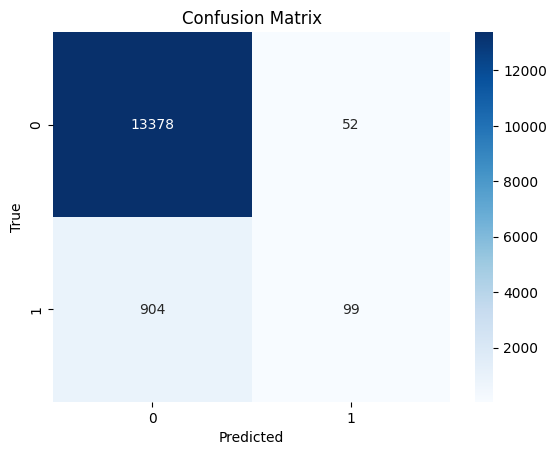

In [78]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_valid, valid_pred)
#cm = confusion_matrix(y_valid, valid_pred_custom)
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()

cm = confusion_matrix(y_valid, valid_pred_custom)


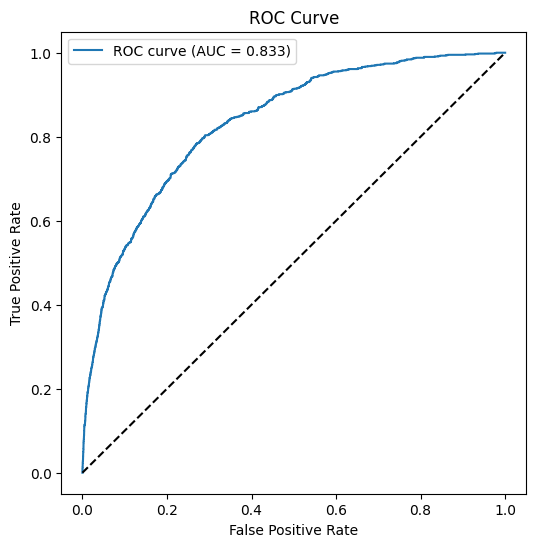

In [59]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_valid, valid_proba)

plt.figure(figsize=(6,6))

plt.plot(fpr, tpr, label=f"ROC curve (AUC = {roc:.3f})")
plt.plot([0,1],[0,1],'k--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")

plt.legend()
plt.show()

In [79]:
feature_importance.head(10)

total_late_payments                0.381025
credit_line_utilization            0.254034
log_debt_ratio                     0.091187
log_income                         0.083342
age                                0.074068
number_of_credit_lines             0.060827
real_estate_loans                  0.030154
number_dependent_family_members    0.025364
dtype: float64

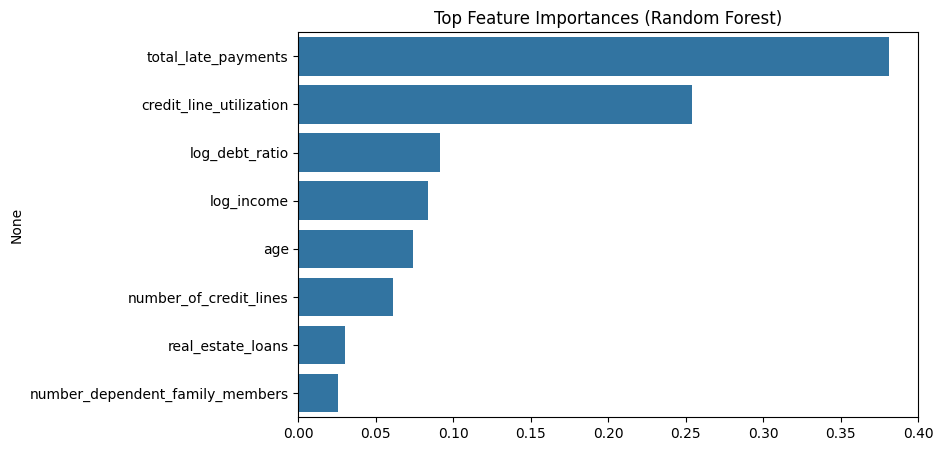

In [80]:
model = best_model.named_steps["model"]

importances = model.feature_importances_

feature_importance = pd.Series(
    importances,
    index=X_train.columns
).sort_values(ascending=False)

plt.figure(figsize=(8,5))

sns.barplot(
    x=feature_importance.values[:10],
    y=feature_importance.index[:10]
)

plt.title("Top Feature Importances (Random Forest)")
plt.show()

Overall we have a good performance without overfitting (can see because  of these two results before tuning treshold (talk about it later with confusion matrix): Best CV ROC-AUC: 0.825567132864049 and Validation ROC-AUC: 0.8425373915483632), we can see that validation > CV which means that model generalizes well and we also have big improvement from LogReg (0.77 vs 0.84), so we can say that already now Random Forest clearly captures non-linear patterns better. From top 10 models we can see the good bias-variance tradeoff that end up in best model as 

{
 'max_depth': 10,
 'max_features': 'sqrt',
 'min_samples_leaf': 2,
 'min_samples_split': 5,
 'n_estimators': 400
}.

Model prefer many trees (more stable predictions), but limit trees complexity that helps to prevent overfitting, also based on min leaf and splits we can see that we smooth trees probably to avoid memorizing noise.

Confusion Matrix is very important here because we almost have no false positives,but MANY false negatives and it misses most defaulters. Thats because when the dataset is imbalances, model probably prefers to predict safe unless very sure. Model is too conservative with threshold 0.5.
I put threshold to 0.4 (so decrease just a little, but still less conservative) and what we can clearly see is that confusion matrix becomes the next

             Pred 0     Pred 1
True 0       9882       3548
True 1        225        778

now we have better recall for class 1, but now we are geting more false positives and we still have some positive missing (225). SO with tuning threshold we are detecting better for true positives but we still have lower precision and too many false positives. So further actins would be based on what is the goal here - if we want to detect as many positives as possible, we need to use low threshold (0.3 0.4), otherwise is we want to avoid false positives we need to use higher threshold. So basically we neeed to decide how conservative we want our model to be. For the final file prediction right now I will simply use untuned threshold model, so we can more clear  compare it with others.

In [82]:
# retrain on FULL data (train + validation)
best_model = grid.best_estimator_
best_model.fit(X, y)

# predict probabilities on test set
test_proba = best_model.predict_proba(X_test_final)[:, 1]

submission = pd.DataFrame({
    "Id": test_ids,
    "Predicted": test_proba
})

submission.to_csv("../data/random_forest_submission.csv", index=False)

print("Submission file created!")

Submission file created!


In [84]:
submission.head()

,Id,Predicted
0,1,0.234030
1,2,0.573685
2,3,0.015086
3,4,0.020661
4,5,0.334841


In [85]:
print(X.shape)
print(X_test_final.shape)
print(submission.shape)
print(submission["Predicted"].min(), submission["Predicted"].max())

(72161, 8)
(48108, 8)
(48108, 2)
0.005540959227491955 0.7788013048598772


In [87]:
submission.isnull().sum()

Id           0
Predicted    0
dtype: int64

In [88]:
submission.describe()

,Id,Predicted
count,48108.000000,48108.000000
mean,24054.500000,0.069431
std,13887.727712,0.095589
min,1.000000,0.005541
25%,12027.750000,0.018053
50%,24054.500000,0.033576
75%,36081.250000,0.076519
max,48108.000000,0.778801
